# Posteos de Revista Anfibia: extracción y exploración inicial

Este notebook parte del dataset generado por `scripts/extract_posteos_anfibia.py`. El recorte principal son posteos editoriales publicados: `post_type == "post"` y `post_status == "publish"`.

`especial` y `web-story` se revisan como anexo metodológico, pero no se mezclan con el corpus principal porque `web-story` es un formato visual distinto y `especial` tiene muy pocos casos.

In [20]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", 120)

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "posteos_anfibia.csv"
DIAGNOSTICS_PATH = PROJECT_ROOT / "data" / "processed" / "posteos_anfibia_diagnostics.json"

assert DATA_PATH.exists(), f"Ejecutar primero: python src/extract_posteos_anfibia.py (Falta {DATA_PATH.name})"
assert DIAGNOSTICS_PATH.exists(), f"Falta archivo de diagnósticos en {DIAGNOSTICS_PATH.name}"

## 1. Carga y diagnóstico del recorte

In [21]:
df = pd.read_csv(DATA_PATH)
for col in ["post_date", "post_date_gmt", "post_modified", "post_modified_gmt"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

with DIAGNOSTICS_PATH.open(encoding="utf-8") as handle:
    diagnostics = json.load(handle)

print(f"Posteos extraídos: {len(df):,}")
print(f"Rango temporal: {df.post_date.min():%Y-%m-%d} a {df.post_date.max():%Y-%m-%d}")
display(pd.Series(diagnostics["checks"], name="count").to_frame())
display(pd.DataFrame(diagnostics["type_status_counts"]).head(20))

Posteos extraídos: 3,622
Rango temporal: 2012-05-14 a 2026-06-16


,count
non_publish_rows,0
non_post_rows,0
duplicate_ids,0
exact_duplicate_document_text_rows,1
empty_titles,1
missing_dates,0
dates_after_dump_date,0
temporal_year_mismatches,0
html_like_body_text_rows,0
email_like_rows,0


,post_type,post_status,rows
0,spnl_log,publish,71546
1,attachment,inherit,27662
2,sp_settings,draft,10455
3,post,publish,3622
4,autor,publish,2288
5,revision,inherit,1608
6,workshops,publish,318
7,attachment,private,294
8,wprss_feed_item,publish,261
9,postman_sent_mail,private,250


## 2. Variables temporales

`post_date` es la fecha principal para análisis temporal. `post_modified` queda disponible para revisar actualizaciones posteriores.

In [22]:
temporal_checks = pd.Series(
    {
        "year_matches": bool((df["post_year"] == df["post_date"].dt.year).all()),
        "month_matches": bool((df["post_month"] == df["post_date"].dt.month).all()),
        "quarter_matches": bool(
            (df["post_quarter"] == df["post_date"].dt.quarter).all()
        ),
        "dates_after_dump_2026_06_17": int(
            (df["post_date"] > pd.Timestamp("2026-06-17")).sum()
        ),
    }
)
display(temporal_checks.to_frame("value"))
display(
    df[
        [
            "ID",
            "title_text",
            "post_date",
            "post_year",
            "post_year_month",
            "post_year_quarter",
            "post_weekday",
            "days_to_modified",
        ]
    ].head()
)

,value
year_matches,True
month_matches,True
quarter_matches,True
dates_after_dump_2026_06_17,0


,ID,title_text,post_date,post_year,post_year_month,post_year_quarter,post_weekday,days_to_modified
0,15668,La China invisible,2012-05-14 13:43:22,2012,2012-05,2012Q2,Monday,4530.939826
1,15706,El rico que se cree Steve Jobs,2012-05-24 13:36:12,2012,2012-05,2012Q2,Thursday,4520.940856
2,15743,La vaca sagrada,2012-06-05 14:52:58,2012,2012-06,2012Q2,Tuesday,4783.841458
3,15695,Los arruinados del Paraná,2012-06-14 10:16:11,2012,2012-06,2012Q2,Thursday,4468.033588
4,15687,De Chile a Tacna: una historia de carniceros y cirujanos,2012-06-25 14:52:05,2012,2012-06,2012Q2,Monday,3699.835891


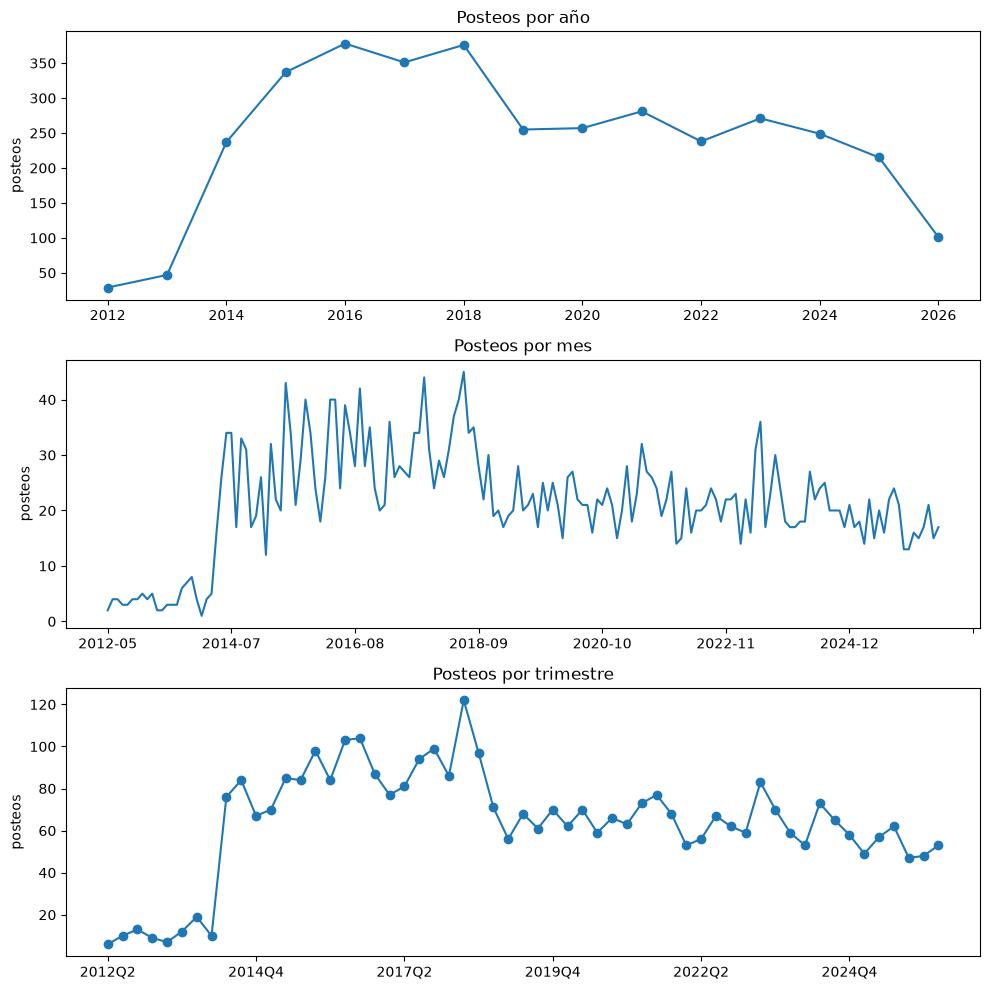

In [23]:
fig, axes = plt.subplots(3, 1, figsize=(10, 10))
df.groupby("post_year").size().plot(ax=axes[0], marker="o", title="Posteos por año")
df.groupby("post_year_month").size().plot(ax=axes[1], title="Posteos por mes")
df.groupby("post_year_quarter").size().plot(
    ax=axes[2], marker="o", title="Posteos por trimestre"
)
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("posteos")
plt.tight_layout()

## 3. Longitud y texto

,word_count
count,3622.000000
mean,2507.997791
std,1471.193378
min,2.000000
25%,1620.000000
50%,2275.500000
75%,3131.500000
max,19677.000000


Text(0, 0.5, 'palabras')

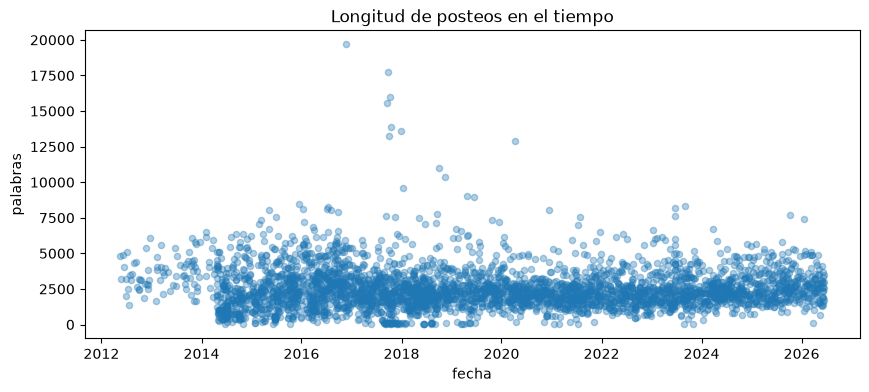

In [24]:
display(df["word_count"].describe().to_frame())
ax = df.plot.scatter(
    x="post_date",
    y="word_count",
    alpha=0.35,
    figsize=(10, 4),
    title="Longitud de posteos en el tiempo",
)
ax.set_xlabel("fecha")
ax.set_ylabel("palabras")

In [25]:
sample = df.sample(min(20, len(df)), random_state=42)
display(
    sample[
        [
            "ID",
            "source_url",
            "post_date",
            "title_text",
            "tagline",
            "copete",
            "autor_names",
            "category",
            "post_tag",
            "word_count",
        ]
    ].sort_values("post_date")
)

,ID,source_url,post_date,title_text,tagline,copete,autor_names,category,post_tag,word_count
32,2697,https://www.revistaanfibia.com/una-guerra-de-sangre-y-fuego-en-el-paraiso-mapuche/,2013-02-13 14:16:47,Una guerra de sangre y fuego en el paraíso mapuche,NaN,"En Temucuicui, la comunidad más guerrera del sur de Chile, los hombres van presos por la ley antiterrorista y los ch...",Carolina Rojas Neculhual; Martín Correa,Política y Economía,NaN,4719
184,2651,https://www.revistaanfibia.com/el-dificil-camino-de-la-soberania-espacial/,2014-07-11 17:21:28,El difícil camino de la soberanía espacial,Tornado II,"En Pipinas, un pueblo de la provincia de Buenos Aires se está construyendo un cohete nacional que permitiría enviar ...",Cintia Kemelmajer,Culturas,NaN,3623
670,37412,https://www.revistaanfibia.com/morales-me-va-a-meter-presa/,2016-02-02 15:10:31,"""Morales me va a meter presa""",Perfil de Milagro Sala,"En un terreno de barro y piedras de Jujuy, sin cooperativa ni experiencia pero con cientos de personas desocupadas, ...",Tali Goldman,Políticas de géneros,NaN,4675
787,44014,https://www.revistaanfibia.com/la-batalla-por-la-igualdad/,2016-05-18 12:01:55,Mujeres militares: la batalla por la igualdad,Fuerzas Armadas,El ascenso a General de una mujer por primera vez en el país da muestra de una de las formas en que las políticas de...,Laura Masson; Julia Muriel Dominzain,Políticas de géneros,NaN,4607
838,46105,https://www.revistaanfibia.com/les-vieilles-narrations-du-present/,2016-07-01 12:55:01,Les vieilles narrations du présent,NaN,"Les appels à rendre le journalisme littéraire, ou l’événement amène, et à raconter des faits réels comme s’il s’agis...",Mónica Bernabé*,Otras,NaN,2330
840,46250,https://www.revistaanfibia.com/archives-declassifier-le-silence/,2016-07-04 10:49:20,Archives : déclassifier le silence,NaN,"40 ans après le dernier coup d’Etat, María Eugenia Ludueña et Luciana Bertoia mènent une enquête exhaustive sur le p...",María Eugenia Ludueña*; Luciana Bertoia*,Otras,NaN,8125
948,50291,https://www.revistaanfibia.com/derechos-hormonas/,2016-10-11 11:55:05,Derechos y hormonas,Atletas trans e intersexuales,"En Estados Unidos, hace 40 años, una atleta ganó un torneo: impugnaron el resultado porque era trans. Hace unas sema...",Mariana Spada; Valeria Pavan,Políticas de géneros,NaN,1981
1025,56054,https://www.revistaanfibia.com/libranos-del-mal/,2016-12-28 11:54:03,Líbranos del mal,Exorcismos,"El exorcismo es popular en cientos de películas donde los curas parecen super héroes. En la vida real, la Iglesia ca...",Verónica Giménez Béliveau,Culturas,NaN,3441
1074,60492,https://www.revistaanfibia.com/fecha-de-vencimiento/,2017-03-07 19:18:47,Fecha de vencimiento,La marcha y el paro,Los trabajadores argentinos volvieron a las calles. Lo hicieron en defensa de la industria nacional y contra los des...,NaN,Política y Economía,NaN,2307
1255,77358,https://www.revistaanfibia.com/gente-que-si/,2017-09-08 16:25:59,Gente que sí,NaN,NaN,NaN,Otras,NaN,94


## 4. Taxonomías y metadatos editoriales

In [26]:
taxonomy_columns = diagnostics["taxonomy_columns"]
taxonomy_columns

['category',
 'destacado',
 'destacado-arriba',
 'destacado-medio',
 'etiquetas-de-recomendados',
 'home-slider',
 'nav_menu',
 'post_format',
 'post_tag',
 'recomendado',
 'slider-en-home',
 'spnl_log_type',
 'super-destacado',
 'text_type',
 'tipo-de-cronica',
 'web_story_category',
 'web_story_media_source',
 'web_story_tag',
 'wp_pattern_category',
 'wp_theme']

In [27]:
taxonomy_columns = diagnostics["taxonomy_columns"]

def split_terms(value):
    if pd.isna(value) or value == "":
        return []
    return [item.strip() for item in str(value).split(";") if item.strip()]

for col in ["category", "post_tag", "text_type"]:
    if col in df.columns:
        exploded = df[["ID", "post_year", col]].copy()
        exploded[col] = exploded[col].map(split_terms)
        exploded = exploded.explode(col).dropna(subset=[col])
        print(f"\nTop {col}")
        display(exploded[col].value_counts().head(20).to_frame("posteos"))


Top category


,posteos
category,
Política y Economía,1431
Culturas,1045
Políticas de géneros,541
Otras,215
Salud,126
Ambiente,113
Tecnologías,109
Educación,91
Amor y sexo,59



Top post_tag


,posteos
post_tag,
Internacional,238
Javier Milei,162
Derechas,114
Zapping cultural,84
Derechos Humanos,77
UNSAM,67
Chile,65
Feminismos,62
Peronismo,61



Top text_type


,posteos
text_type,
Ensayo,1505
Crónica,1112


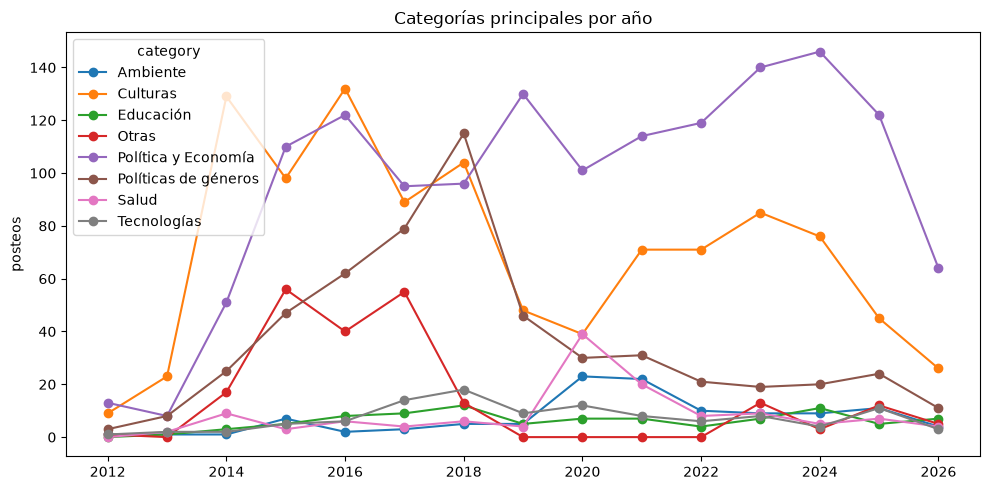

In [28]:
if "category" in df.columns:
    cats = df[["ID", "post_year", "category"]].copy()
    cats["category"] = cats["category"].map(split_terms)
    cats = cats.explode("category").dropna(subset=["category"])
    top_categories = cats["category"].value_counts().head(8).index
    pivot = cats[cats["category"].isin(top_categories)].pivot_table(
        index="post_year",
        columns="category",
        values="ID",
        aggfunc="count",
        fill_value=0,
    )
    pivot.plot(figsize=(10, 5), marker="o", title="Categorías principales por año")
    plt.xlabel("")
    plt.ylabel("posteos")
    plt.tight_layout()

## 5. Auditoría de completitud

In [29]:
audit_columns = [
    "title_text",
    "post_date",
    "body_text",
    "autor_names",
    "copete",
    "tagline",
    "category",
    "post_tag",
    "text_type",
]
audit = {}
for col in audit_columns:
    if col in df.columns:
        audit[col] = int(
            df[col].isna().sum() + df[col].fillna("").astype(str).eq("").sum()
        )
display(
    pd.Series(audit, name="missing_or_empty")
    .to_frame()
    .sort_values("missing_or_empty", ascending=False)
)

,missing_or_empty
post_tag,4060
text_type,2010
autor_names,506
tagline,338
copete,242
body_text,26
title_text,2
post_date,0
category,0


## 6. Anexo: `especial` y `web-story`

El pipeline no los mezcla con el corpus principal. Los diagnósticos dejan sus conteos y longitud para decidir una inclusión posterior.

In [30]:
print("Cantidad")
display(pd.Series(diagnostics["adjunct_counts"], name="published_rows").to_frame())
print("Palabras")
display(pd.DataFrame(diagnostics["adjunct_word_stats"]).T)

Cantidad


,published_rows
web-story,80
especial,13


Palabras


,count,median,mean,max
especial,13.0,219.0,238.54,644.0
web-story,80.0,1010.5,1111.30,2847.0
